In [1]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt

#we've been working with these 3 but the next 2 are statistical libraries to help us run the regression

In [2]:
from scipy import stats
import statsmodels.api as sm

In [3]:
import yfinance as yf

In [4]:
tickers = ['AAPL','^TNX']
apple = yf.download(tickers,start='2015-01-01', auto_adjust=True)
apple = apple['Close']


c:\Users\vince\Portfolio_project\.venv\Lib\site-packages\yfinance\utils.py:568: Pandas4Warning: The inplace keyword in DataFrame.sort_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  quotes.sort_index(inplace=True)
c:\Users\vince\Portfolio_project\.venv\Lib\site-packages\yfinance\utils.py:514: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.drop(
c:\Users\vince\Portfolio_project\.venv\Lib\site-packages\yfinance\utils.py:518: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  df.rename(columns={
[                       0%           

In [5]:
apple

Ticker,AAPL,^TNX
Date,,
2015-01-02,24.153400,2.123
2015-01-05,23.472965,2.039
2015-01-06,23.475172,1.963
2015-01-07,23.804346,1.954
2015-01-08,24.718967,2.016
...,...,...
2026-11-11,355.359985,4.998
2026-11-12,354.880005,5.103
2026-11-13,356.269989,5.154


In [6]:
# X = (apple['^IRX'] - apple['^IRX'].shift(1)).dropna()
# Y = apple['AAPL'].pct_change().dropna()

df = pd.DataFrame({
    'X': (apple['^TNX'] - apple['^TNX'].shift(1))/ 100,
    'Y': apple['AAPL'].pct_change()
}).dropna()

X = df['X']
Y = df['Y']

In [7]:
X

Date
2015-01-05   -0.00084
2015-01-06   -0.00076
2015-01-07   -0.00009
2015-01-08    0.00062
2015-01-09   -0.00045
               ...   
2026-11-11    0.00015
2026-11-12    0.00105
2026-11-13    0.00051
2026-11-16   -0.00033
2026-11-17   -0.00018
Name: X, Length: 2984, dtype: float64

In [8]:
Y

Date
2015-01-05   -0.028171
2015-01-06    0.000094
2015-01-07    0.014022
2015-01-08    0.038422
2015-01-09    0.001072
                ...   
2026-11-11    0.020430
2026-11-12   -0.001351
2026-11-13    0.003917
2026-11-16   -0.009796
2026-11-17   -0.002466
Name: Y, Length: 2984, dtype: float64

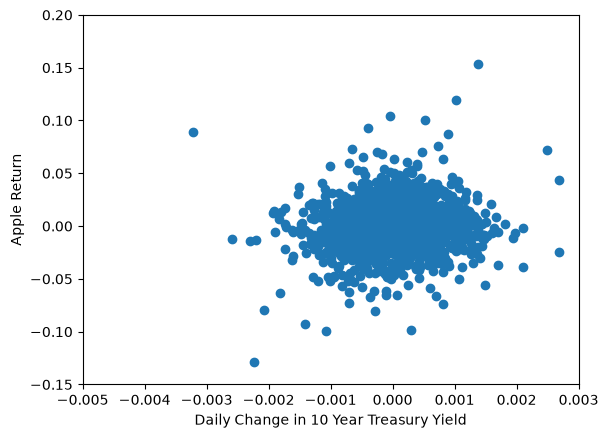

In [11]:
#does the change in interest rate (T-Bill for proxy) affect the return on Apple?

plt.scatter(X,Y)
plt.axis([-0.005, 0.003, -0.15, 0.2])
plt.ylabel('Apple Return')
plt.xlabel('Daily Change in 10 Year Treasury Yield')
plt.show() #not needed in jupyter but still

In [12]:
#regression
X1 = sm.add_constant(X)
regression = sm.OLS(Y,X1).fit()
regression.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                            OLS Regression Results                            
==============================================================================
Dep. Variable:                      Y   R-squared:                       0.007
Model:                            OLS   Adj. R-squared:                  0.007
Method:                 Least Squares   F-statistic:                     20.79
Date:                Tue, 17 Nov 2026   Prob (F-statistic):           5.34e-06
Time:                        20:57:59   Log-Likelihood:                 7757.1
No. Observations:                2984   AIC:                        -1.551e+04
Df Residuals:                    2982   BIC:                        -1.550e+04
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
==============================================================================
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0010      0.000      3.159      0.002       0.000       0.002
X              2.8207      0.619      4.559      0.000       1.608       4.034
==============================================================================
Omnibus:                      393.997   Durbin-Watson:                   2.090
Prob(Omnibus):                  0.000   Jarque-Bera (JB):             4544.047
Skew:                           0.136   Prob(JB):                         0.00
Kurtosis:                       9.039   Cond. No.                     1.88e+03
==============================================================================

Notes:
[1] Standard Errors assume that the covariance matrix of the errors is correctly specified.
[2] The condition number is large, 1.88e+03. This might indicate that there are
strong multicollinearity or other numerical problems.
"""

For R-squared, it shows there is very little relationship here with the daily change in the 10 Year treasury yield and apple's daily returns (ie Daily changes in 10 yr treasury yield explain only 0.7% of the variation in Apple's daily returns)

with our p-value being 0.000534% (basically zero), we can still consider this regression to be statistically significant (given we have nearly 3000 days to back it up). The p-value near zero means there is basically zero probability that our observed pattern happened by just pure luck (especially under standard significance levels of 5%)(0.000534% < 5% (ie p-value < significance level))

though there is very little relationship between the 2, the B1 coefficient of +2.82 shows a slightly positive relationship (ie Apple's stock tends to rise a little bit when the 10 yr treasury rises)

significance proves the pattern is real, R-squared measures the strength of that pattern. Given are gigantic sample size, we can reliably detect this weak signal